Using device: cpu
Classes: ['Mild', 'Moderate', 'Normal', 'Proliferate', 'Severe']
Number of classes: 5

Epoch 1/30
Train Acc: 62.89% | Val Acc: 86.36% | Val F1: 0.8551
Saved Best Model

Epoch 2/30
Train Acc: 92.45% | Val Acc: 77.27% | Val F1: 0.7250

Epoch 3/30
Train Acc: 97.48% | Val Acc: 77.27% | Val F1: 0.7168

Epoch 4/30
Train Acc: 98.11% | Val Acc: 88.64% | Val F1: 0.8796
Saved Best Model

Epoch 5/30
Train Acc: 99.37% | Val Acc: 90.91% | Val F1: 0.9065
Saved Best Model

Epoch 6/30
Train Acc: 99.37% | Val Acc: 93.18% | Val F1: 0.9314
Saved Best Model

Epoch 7/30
Train Acc: 98.11% | Val Acc: 93.18% | Val F1: 0.9314

Epoch 8/30
Train Acc: 99.37% | Val Acc: 93.18% | Val F1: 0.9314

Epoch 9/30
Train Acc: 100.00% | Val Acc: 100.00% | Val F1: 1.0000
Saved Best Model

Epoch 10/30
Train Acc: 100.00% | Val Acc: 100.00% | Val F1: 1.0000

Epoch 11/30
Train Acc: 99.37% | Val Acc: 88.64% | Val F1: 0.8842

Epoch 12/30
Train Acc: 99.37% | Val Acc: 97.73% | Val F1: 0.9777

Epoch 13/30
Train Acc: 

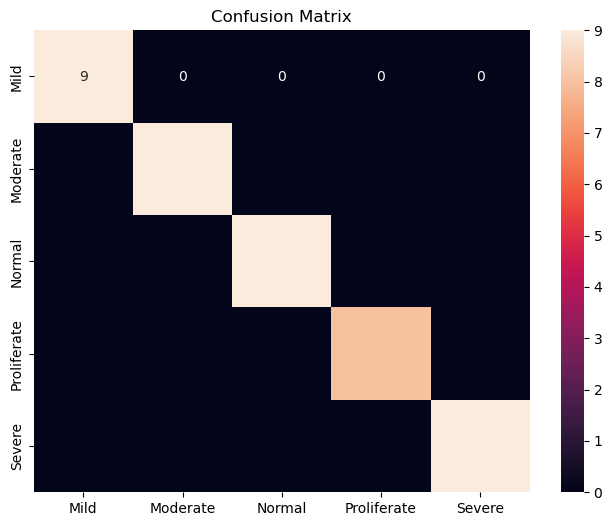

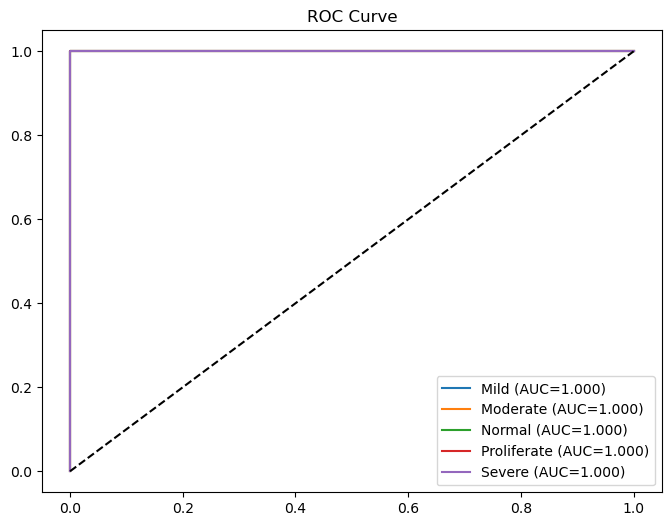

In [7]:
# ==================== IMPORTS ====================
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import models, transforms
from torchvision.datasets import ImageFolder
from sklearn.metrics import (
    f1_score, confusion_matrix, classification_report,
    roc_curve, auc, precision_recall_curve
)
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# ==================== CONFIG ====================
IMG_SIZE = 128
BATCH_SIZE = 16
EPOCHS = 30
LEARNING_RATE = 3e-4
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)

# ==================== PATHS ====================
TRAIN_PATH = 'D:/Feb2026/Project/diabetic_retinopathy/OCT/train'
VAL_PATH = 'D:/Feb2026/Project/diabetic_retinopathy/OCT/val'

# ==================== TRANSFORMS ====================
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

# ==================== DATASETS ====================
train_dataset = ImageFolder(TRAIN_PATH, transform=train_transform)
val_dataset = ImageFolder(VAL_PATH, transform=val_transform)

num_classes = len(train_dataset.classes)
print("Classes:", train_dataset.classes)
print("Number of classes:", num_classes)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

# ==================== MODEL ====================
class LightweightCNN(nn.Module):
    def __init__(self):
        super().__init__()
        base = models.mobilenet_v3_large(weights=models.MobileNet_V3_Large_Weights.IMAGENET1K_V1)
        self.features = base.features
        self.feat_dim = 960

        self.channel_attn = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(self.feat_dim, self.feat_dim//8, 1),
            nn.ReLU(),
            nn.Conv2d(self.feat_dim//8, self.feat_dim, 1),
            nn.Sigmoid()
        )

        self.spatial_attn = nn.Sequential(
            nn.Conv2d(2,1,kernel_size=7,padding=3),
            nn.Sigmoid()
        )

    def forward(self,x):
        x = self.features(x)
        x = x * self.channel_attn(x)

        avg_out = torch.mean(x,dim=1,keepdim=True)
        max_out,_ = torch.max(x,dim=1,keepdim=True)
        spatial = torch.cat([avg_out,max_out],dim=1)
        x = x * self.spatial_attn(spatial)

        x = F.adaptive_avg_pool2d(x,1)
        return x.view(x.size(0),-1)

class LightweightViT(nn.Module):
    def __init__(self, img_size=128, patch=16, embed_dim=256, depth=6, heads=4):
        super().__init__()
        self.patch_embed = nn.Conv2d(3, embed_dim, kernel_size=patch, stride=patch)
        self.num_patches = (img_size//patch)**2
        self.pos_embed = nn.Parameter(torch.randn(1,self.num_patches,embed_dim)*0.02)

        encoder = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=heads,
            dim_feedforward=embed_dim*4,
            dropout=0.2,
            activation='gelu',
            batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder, num_layers=depth)
        self.norm = nn.LayerNorm(embed_dim)

    def forward(self,x):
        x = self.patch_embed(x)
        x = x.flatten(2).transpose(1,2)
        x = x + self.pos_embed
        x = self.transformer(x)
        x = x.mean(dim=1)
        return self.norm(x)

class FastFusionModel(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.cnn = LightweightCNN()
        self.vit = LightweightViT()

        self.classifier = nn.Sequential(
            nn.Linear(960+256,512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512,256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256,num_classes)
        )

    def forward(self,x):
        cnn_feat = self.cnn(x)
        vit_feat = self.vit(x)
        combined = torch.cat([cnn_feat,vit_feat],dim=1)
        return self.classifier(combined)

model = FastFusionModel(num_classes).to(device)

# ==================== LOSS + OPTIMIZER ====================
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE)

# ==================== TRAINING ====================
history = {'train_acc':[], 'val_acc':[], 'train_loss':[], 'val_loss':[]}
best_f1 = 0

for epoch in range(EPOCHS):
    print(f"\nEpoch {epoch+1}/{EPOCHS}")

    model.train()
    train_correct,total,train_loss = 0,0,0

    for imgs,labels in train_loader:
        imgs,labels = imgs.to(device),labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs,labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        _,pred = outputs.max(1)
        total += labels.size(0)
        train_correct += pred.eq(labels).sum().item()

    train_acc = 100*train_correct/total

    model.eval()
    val_correct,val_total,val_loss = 0,0,0
    val_preds,val_labels = [],[]

    with torch.no_grad():
        for imgs,labels in val_loader:
            imgs,labels = imgs.to(device),labels.to(device)
            outputs = model(imgs)
            loss = criterion(outputs,labels)

            val_loss += loss.item()
            _,pred = outputs.max(1)

            val_total += labels.size(0)
            val_correct += pred.eq(labels).sum().item()
            val_preds.extend(pred.cpu().numpy())
            val_labels.extend(labels.cpu().numpy())

    val_acc = 100*val_correct/val_total
    val_f1 = f1_score(val_labels,val_preds,average='macro')

    print(f"Train Acc: {train_acc:.2f}% | Val Acc: {val_acc:.2f}% | Val F1: {val_f1:.4f}")

    if val_f1 > best_f1:
        best_f1 = val_f1
        torch.save(model.state_dict(),'best_model_5class.pth')
        print("Saved Best Model")

    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)
    history['train_loss'].append(train_loss/len(train_loader))
    history['val_loss'].append(val_loss/len(val_loader))

print("Best F1:", best_f1)

# ==================== FINAL EVALUATION ====================
model.load_state_dict(torch.load('best_model_5class.pth'))
model.eval()

all_preds,all_labels,all_probs = [],[],[]

with torch.no_grad():
    for imgs,labels in val_loader:
        imgs = imgs.to(device)
        outputs = model(imgs)
        probs = torch.softmax(outputs,dim=1)
        _,pred = outputs.max(1)

        all_preds.extend(pred.cpu().numpy())
        all_labels.extend(labels.numpy())
        all_probs.extend(probs.cpu().numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)
all_probs = np.array(all_probs)

print("\nClassification Report:")
print(classification_report(all_labels,all_preds,target_names=train_dataset.classes))

# ==================== CONFUSION MATRIX ====================
cm = confusion_matrix(all_labels,all_preds)
plt.figure(figsize=(8,6))
sns.heatmap(cm,annot=True,fmt='d',
            xticklabels=train_dataset.classes,
            yticklabels=train_dataset.classes)
plt.title("Confusion Matrix")
plt.show()

# ==================== ROC CURVE ====================
y_bin = label_binarize(all_labels, classes=range(num_classes))
plt.figure(figsize=(8,6))
for i in range(num_classes):
    fpr,tpr,_ = roc_curve(y_bin[:,i],all_probs[:,i])
    roc_auc = auc(fpr,tpr)
    plt.plot(fpr,tpr,label=f"{train_dataset.classes[i]} (AUC={roc_auc:.3f})")

plt.plot([0,1],[0,1],'k--')
plt.legend()
plt.title("ROC Curve")
plt.show()

In [8]:
# ==================== IMAGE PREDICTION FUNCTION ====================
from PIL import Image

def predict_image(image_path, model, class_names):
    model.eval()
    
    # Same transform as validation
    transform = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406],
                             [0.229, 0.224, 0.225])
    ])
    
    image = Image.open(image_path).convert('RGB')
    input_tensor = transform(image).unsqueeze(0).to(device)
    
    with torch.no_grad():
        outputs = model(input_tensor)
        probabilities = torch.softmax(outputs, dim=1)
        confidence, predicted_class = torch.max(probabilities, 1)
    
    predicted_label = class_names[predicted_class.item()]
    confidence_score = confidence.item() * 100
    
    print(f"\nPrediction Result")
    print(f"Image: {image_path}")
    print(f"Predicted Class: {predicted_label}")
    print(f"Confidence: {confidence_score:.2f}%")
    
    return predicted_label, confidence_score

In [10]:
test_image_path = "D:/Feb2026/Project/diabetic_retinopathy/825.png"
predict_image(test_image_path, model, train_dataset.classes)


Prediction Result
Image: D:/Feb2026/Project/diabetic_retinopathy/825.png
Predicted Class: Normal
Confidence: 98.01%


('Normal', 98.0136513710022)